# Lab 08 – Lab Task 6.1: Object Detection Using R-CNN
**Course:** Computer Vision (AI-4002)

In the manual we studied the R-CNN family (R-CNN → Fast R-CNN → Faster R-CNN) and ran Faster R-CNN on the BCCD blood-cell dataset.
The **Lab Task** asks us to:

> Implement object detection using a Regional Convolutional Neural Network (R-CNN) on a dataset of our choice (**not** BCCD). R-CNN combines **region proposal, feature extraction and object classification** to identify and localize objects.

This notebook does exactly that, step by step, following the **same structure as the manual**:

| Manual section | What we do in this notebook |
|---|---|
| 3. Problem statement | Choose our own dataset (Raccoon detection) |
| 4. Data exploration | Load CSV, inspect images, class counts, draw ground-truth boxes |
| 5.2 Convert CSV → text format | Create `annotate.txt` in `filepath,x1,y1,x2,y2,class_name` format |
| 2.1 R-CNN workflow | Selective Search → warp regions → CNN features → SVM classifier + box regressor |
| 5.4 Running inference | Predict on test images and **save** them in a `predictions/` folder |
| 2.4 Comparison | Measure prediction time per image and compare with Fast / Faster R-CNN |

## 0. Dataset Choice

| | |
|---|---|
| **Dataset** | Raccoon Detection Dataset (by Dat Tran) |
| **Link** | 🔗 https://github.com/datitran/raccoon_dataset |
| **Size** | 200 images (~14 MB), 217 bounding boxes |
| **Classes** | 1 class: `raccoon` |
| **Annotations** | CSV file with `filename, width, height, class, xmin, ymin, xmax, ymax` (almost identical to the BCCD `train.csv` in the manual) |
| **Split** | Ready-made `train_labels.csv` (160 images) and `test_labels.csv` (40 images) |

**Why this dataset?**
* It is **small**, so it downloads in seconds and trains quickly, even on a free Colab CPU.
* The annotation format is the **same style as the manual's CSV**, so every step maps one-to-one.
* It has **one object class**, so R-CNN's job is a clear yes/no question for each region: *"raccoon or background?"*.

## 1. Quick Recap: How R-CNN Works

R-CNN (Section 2.1 of the manual) detects objects in **4 steps**:

```
 Input image
     │
     ▼
 [Step 1] Region Proposals ── Selective Search gives ~2000 candidate boxes (Regions of Interest)
     │
     ▼
 [Step 2] Warp + CNN ──────── every region is cropped, resized (warped) to the same size and
     │                         passed *separately* through a CNN to get a feature vector
     ▼
 [Step 3] Classify ────────── an SVM looks at the feature vector: "raccoon" or "background"?
     │
     ▼
 [Step 4] Bounding-box regressor fine-tunes the box, then Non-Max Suppression removes duplicates
```

R-CNN uses **three separate models**: the CNN, the SVMs and the bounding-box regressors. Passing every region through the CNN separately is exactly why R-CNN is slow (40–50 s/image in the manual's comparison table). We will measure this ourselves at the end.

## 2. Setup

### 2.1 Install and import libraries
`selectivesearch` is a small Python library that implements the **Selective Search** region-proposal algorithm used by R-CNN.

In [ ]:
!pip install -q selectivesearch

In [ ]:
# importing required libraries
import os
import time
import random
import warnings

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib import patches
import selectivesearch

from sklearn.svm import LinearSVC
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
%matplotlib inline

# make results repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Libraries imported ✅")

Libraries imported ✅


### 2.2 Settings (all the numbers you may want to change are here)
If something is too slow on your computer, **reduce `NUM_TRAIN_IMAGES` / `NUM_TEST_IMAGES`**. If you want better accuracy, increase them (the dataset has 160 train / 40 test images).

In [ ]:
# ---------------- Settings ----------------
MAX_SIDE = 300            # every image is resized so its longest side is 300 px (makes Selective Search fast)

NUM_TRAIN_IMAGES = 160    # how many training images to use  (max 160)
NUM_TEST_IMAGES  = 40     # how many test images to use      (max 40)

POS_IOU = 0.5             # region with IoU >= 0.5 with a ground-truth box  -> "raccoon"  (positive)
NEG_IOU = 0.3             # region with IoU <  0.3 with every ground-truth box -> "background" (negative)
MAX_POS_PER_IMAGE = 16    # max positive regions we keep from one training image
MAX_NEG_PER_IMAGE = 48    # max negative regions we keep from one training image

MAX_TEST_PROPOSALS = 300  # max number of Selective Search regions we classify per test image
NMS_IOU    = 0.3          # Non-Max Suppression overlap threshold
SCORE_THRESH = 0.5        # only keep detections whose SVM score is above this value

DATA_ROOT = "raccoon_dataset"
IMG_DIR   = f"{DATA_ROOT}/images"

### 2.3 Download the dataset
We simply clone the GitHub repository (same idea as step 5.1 of the manual, where we cloned `keras-frcnn`).

In [ ]:
if not os.path.exists(DATA_ROOT):
    !git clone https://github.com/datitran/raccoon_dataset.git
else:
    print("Dataset already downloaded ✅")

print("Number of image files:", len(os.listdir(IMG_DIR)))

Dataset already downloaded ✅
Number of image files: 200


## 3. Data Exploration (Manual Section 4)

### 3.1 Dataset structure and files
Just like the manual's `train_images`, `test_images` and `train.csv`, our dataset has:

* `images/` – all the pictures (`raccoon-1.jpg`, `raccoon-2.jpg`, …)
* `data/train_labels.csv` – boxes for the **training** images (we use this to train the model)
* `data/test_labels.csv` – boxes for the **test** images (we keep these hidden during training and only use them to *check* our predictions)

Each CSV can have **several rows for one image** because one image can contain more than one object.

### 3.2 Loading and inspecting the annotation CSV

In [ ]:
# read the csv files using read_csv function of pandas
train = pd.read_csv(f"{DATA_ROOT}/data/train_labels.csv")
test  = pd.read_csv(f"{DATA_ROOT}/data/test_labels.csv")

# rename two columns so they match the manual's naming (image_names / class name)
train = train.rename(columns={"filename": "image_names", "class": "class_name"})
test  = test.rename(columns={"filename": "image_names", "class": "class_name"})

train.head()

,image_names,width,height,class_name,xmin,ymin,xmax,ymax
0,raccoon-17.jpg,259,194,raccoon,95,60,167,118
1,raccoon-11.jpg,660,432,raccoon,3,1,461,431
2,raccoon-63.jpg,600,400,raccoon,74,107,280,290
3,raccoon-63.jpg,600,400,raccoon,227,93,403,298
4,raccoon-60.jpg,273,185,raccoon,58,33,197,127


There are **8 columns** in the file. Let's understand what each column represents:

* **image_names:** name of the image file
* **width, height:** size of the original image in pixels
* **class_name:** the type of object (here always `raccoon`; in the manual it was `cell_type`)
* **xmin:** x-coordinate of the **top-left** corner of the box
* **ymin:** y-coordinate of the **top-left** corner of the box
* **xmax:** x-coordinate of the **bottom-right** corner of the box
* **ymax:** y-coordinate of the **bottom-right** corner of the box

> 📝 In images the origin (0, 0) is the **top-left** corner and *y grows downwards*. (The manual calls the corners "bottom-left / top-right", but the idea is the same: `xmin,ymin` and `xmax,ymax` are two opposite corners of the box.)

### 3.3 Inspecting images and class distribution

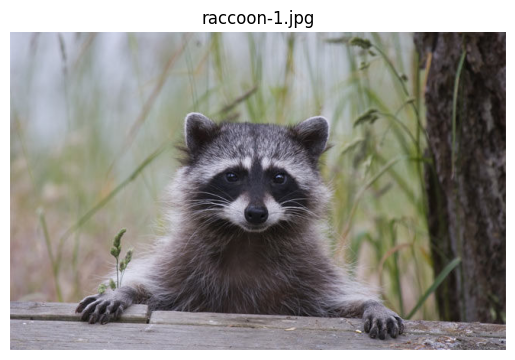

Image shape (height, width, channels): (417, 650, 3)


In [ ]:
# reading a single image using imread function of matplotlib
image = plt.imread(f"{IMG_DIR}/raccoon-1.jpg")
plt.imshow(image)
plt.title("raccoon-1.jpg")
plt.axis("off")
plt.show()
print("Image shape (height, width, channels):", image.shape)

In [ ]:
# Number of unique images
print("Training images :", train["image_names"].nunique())
print("Test images     :", test["image_names"].nunique())

# Number of objects per class
print("\nTraining set - number of objects per class:")
print(train["class_name"].value_counts())

print("\nTest set - number of objects per class:")
print(test["class_name"].value_counts())

Training images : 160
Test images     : 40

Training set - number of objects per class:
class_name
raccoon    173
Name: count, dtype: int64

Test set - number of objects per class:
class_name
raccoon    44
Name: count, dtype: int64


In [ ]:
# How many objects does one image usually contain?
objects_per_image = train.groupby("image_names").size()
print(objects_per_image.value_counts().rename_axis("objects in image").rename("number of images"))

objects in image
1    148
2     11
3      1
Name: number of images, dtype: int64


### 3.4 Visualizing ground-truth bounding boxes
Let's draw the real (hand-labelled) boxes on an image, exactly like the manual does with `patches.Rectangle`.

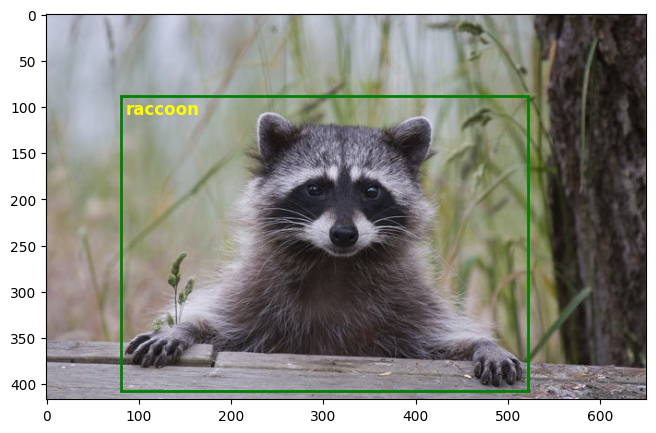

In [ ]:
def show_ground_truth(image_name, df):
    fig = plt.figure(figsize=(6, 5))
    # add axes to the image
    ax = fig.add_axes([0, 0, 1, 1])

    # read and plot the image
    image = plt.imread(f"{IMG_DIR}/{image_name}")
    plt.imshow(image)

    # iterating over the image for different objects
    for _, row in df[df.image_names == image_name].iterrows():
        xmin, xmax, ymin, ymax = row.xmin, row.xmax, row.ymin, row.ymax
        width  = xmax - xmin
        height = ymax - ymin

        # add bounding boxes to the image
        rect = patches.Rectangle((xmin, ymin), width, height, edgecolor="g", linewidth=2, facecolor="none")
        ax.add_patch(rect)
        ax.annotate(row.class_name, xy=(xmin + 5, ymin + 20), color="yellow", fontsize=12, weight="bold")
    plt.show()

show_ground_truth("raccoon-1.jpg", train)

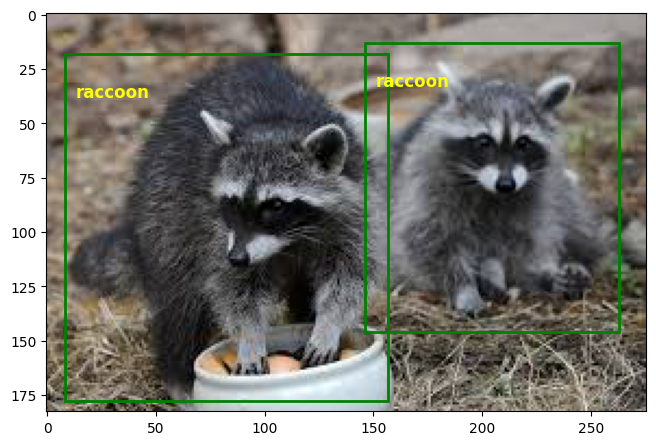

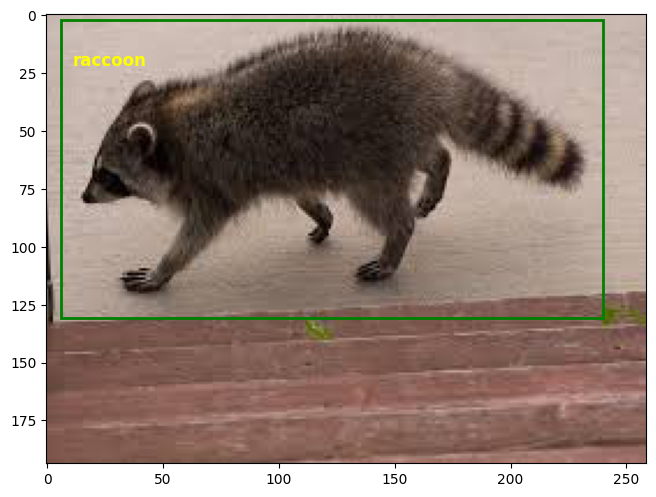

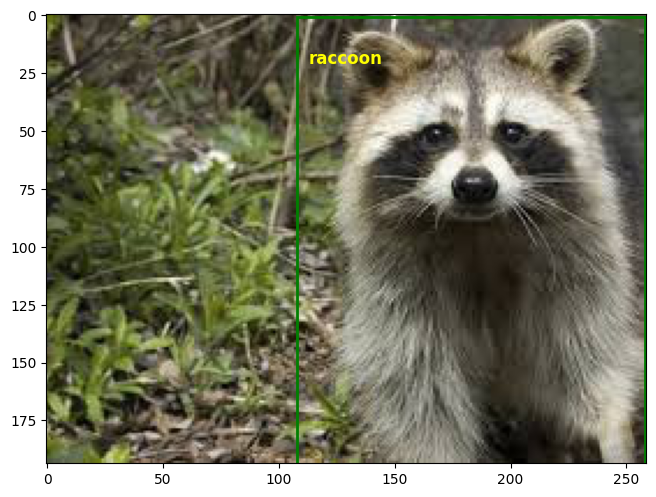

In [ ]:
# a few more random training images
sample_names = train["image_names"].drop_duplicates().sample(3, random_state=SEED).tolist()
for name in sample_names:
    show_ground_truth(name, train)

This is what a training example looks like: the image plus its ground-truth box(es). Our R-CNN will learn from these examples and then predict boxes on the unseen test images.

## 4. Converting CSV Annotations to the Text Format (Manual Section 5.2)

In the manual, `keras-frcnn` needed annotations in this format:

```
filepath,x1,y1,x2,y2,class_name
```

Our own R-CNN code reads the CSV directly, so we do not *need* this file, but we create it here to follow the manual and to have a ready-made file if you later want to try `keras-frcnn` on this dataset.

In [ ]:
# Create a new DataFrame for the annotation format
data = pd.DataFrame()

# Copy the image names from the training data
data["format"] = train["image_names"]

# Vectorized path prefixing
data["format"] = IMG_DIR + "/" + data["format"]

# Vectorized string concatenation for coordinates and class names
# Note: keras-frcnn expects path,x1,y1,x2,y2,class_name order
data["format"] = (
    data["format"] + "," +
    train["xmin"].astype(str) + "," +
    train["ymin"].astype(str) + "," +
    train["xmax"].astype(str) + "," +
    train["ymax"].astype(str) + "," +
    train["class_name"]
)

# Save to a text file without headers or row indices
data.to_csv("annotate.txt", header=None, index=None, sep=" ")

# show the first 3 lines of the file we just created
with open("annotate.txt") as f:
    for _ in range(3):
        print(f.readline().strip())

raccoon_dataset/images/raccoon-17.jpg,95,60,167,118,raccoon
raccoon_dataset/images/raccoon-11.jpg,3,1,461,431,raccoon
raccoon_dataset/images/raccoon-63.jpg,74,107,280,290,raccoon


## 5. Implementing R-CNN Step by Step

### 5.1 Helper functions
Before building the pipeline we need a few small tools.

* `load_image` – reads an image, resizes it (longest side = `MAX_SIDE`) and rescales its ground-truth boxes by the same factor.
* `iou_matrix` – **IoU (Intersection over Union)** measures how much two boxes overlap (0 = no overlap, 1 = identical). R-CNN uses it to decide which regions are "raccoon" and which are "background".

In [ ]:
def load_image(image_name, df=None):
    # Read an image (RGB), resize it, and return the image + its ground-truth boxes (resized too).
    img = cv2.imread(f"{IMG_DIR}/{image_name}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]
    scale = MAX_SIDE / max(h, w)
    img = cv2.resize(img, (int(round(w * scale)), int(round(h * scale))))

    gt_boxes = np.zeros((0, 4), dtype=np.float32)
    if df is not None:
        rows = df[df.image_names == image_name]
        gt_boxes = rows[["xmin", "ymin", "xmax", "ymax"]].values.astype(np.float32) * scale
    return img, gt_boxes


def iou_matrix(boxes_a, boxes_b):
    # IoU between every box in boxes_a (N,4) and every box in boxes_b (M,4). Boxes are [x1, y1, x2, y2].
    boxes_a = np.asarray(boxes_a, dtype=np.float32).reshape(-1, 4)
    boxes_b = np.asarray(boxes_b, dtype=np.float32).reshape(-1, 4)

    # corners of the overlapping area
    x1 = np.maximum(boxes_a[:, None, 0], boxes_b[None, :, 0])
    y1 = np.maximum(boxes_a[:, None, 1], boxes_b[None, :, 1])
    x2 = np.minimum(boxes_a[:, None, 2], boxes_b[None, :, 2])
    y2 = np.minimum(boxes_a[:, None, 3], boxes_b[None, :, 3])

    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (boxes_a[:, 2] - boxes_a[:, 0]) * (boxes_a[:, 3] - boxes_a[:, 1])
    area_b = (boxes_b[:, 2] - boxes_b[:, 0]) * (boxes_b[:, 3] - boxes_b[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return inter / np.maximum(union, 1e-6)


# quick sanity check: identical boxes -> 1.0, half-overlapping boxes -> 0.33, far-apart boxes -> 0.0
print(iou_matrix([[0, 0, 10, 10]], [[0, 0, 10, 10], [5, 0, 15, 10], [20, 20, 30, 30]]))

[[1.         0.33333334 0.        ]]


### 5.2 Step 1 – Region proposals with Selective Search
Instead of sliding a window over every possible position, **Selective Search** groups pixels with similar colour/texture into segments and merges them step by step. Every segment gives a candidate box ("Region of Interest"). The manual says R-CNN extracts ~2000 of them per image; our images are small, so we get fewer.

In [ ]:
def get_proposals(img, max_boxes=None):
    # Run Selective Search and return a clean list of boxes [x1, y1, x2, y2].
    _, regions = selectivesearch.selective_search(img, scale=100, sigma=0.8, min_size=30)

    boxes, seen = [], set()
    for r in regions:
        x, y, w, h = r["rect"]
        if (x, y, w, h) in seen:                  # skip duplicates
            continue
        if w < 20 or h < 20:                      # skip tiny regions
            continue
        if w / h > 4 or h / w > 4:                # skip extremely thin regions
            continue
        seen.add((x, y, w, h))
        boxes.append([x, y, x + w, y + h])

    boxes = np.array(boxes, dtype=np.float32).reshape(-1, 4)
    if max_boxes is not None and len(boxes) > max_boxes:
        keep = np.random.RandomState(SEED).choice(len(boxes), max_boxes, replace=False)
        boxes = boxes[keep]
    return boxes


img, gt = load_image("raccoon-1.jpg", train)
t0 = time.time()
proposals = get_proposals(img)
print(f"Selective Search found {len(proposals)} regions in {time.time() - t0:.2f} s")

# Did Selective Search find at least one box that matches the real raccoon well?
best_iou = iou_matrix(proposals, gt).max()
print(f"Best IoU between a proposal and the ground-truth box: {best_iou:.2f}")

Selective Search found 106 regions in 0.51 s
Best IoU between a proposal and the ground-truth box: 0.56


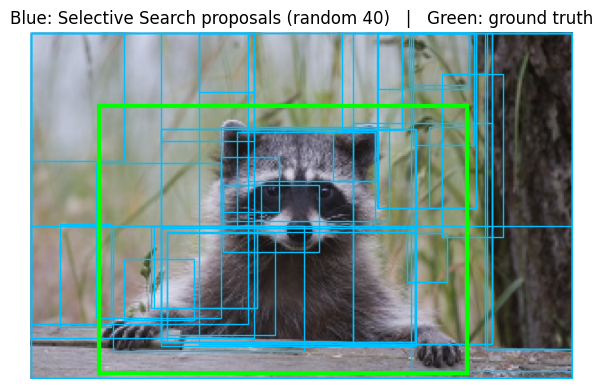

In [ ]:
# Visualize 40 random proposals (blue) and the ground-truth box (green)
fig, ax = plt.subplots(1, figsize=(7, 5))
ax.imshow(img)
for (x1, y1, x2, y2) in proposals[np.random.RandomState(0).choice(len(proposals), 40, replace=False)]:
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor="deepskyblue", linewidth=1, facecolor="none"))
for (x1, y1, x2, y2) in gt:
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor="lime", linewidth=3, facecolor="none"))
ax.set_title("Blue: Selective Search proposals (random 40)   |   Green: ground truth")
ax.axis("off")
plt.show()

**How good are the proposals overall?** Since the proposals are the *only* places R-CNN will look, if none of them overlaps the raccoon, the detector can never find it. Let's check on the first 30 training images what share of ground-truth boxes has at least one proposal with IoU ≥ 0.5 (this is called *recall of the proposals*).

In [ ]:
found, total = 0, 0
names = train["image_names"].drop_duplicates().tolist()[:30]
for name in names:
    im, g = load_image(name, train)
    p = get_proposals(im)
    best = iou_matrix(p, g).max(axis=0)       # best proposal for every ground-truth box
    found += (best >= 0.5).sum()
    total += len(g)
print(f"Ground-truth boxes covered by a proposal with IoU >= 0.5: {found}/{total} = {found / total:.0%}")

Ground-truth boxes covered by a proposal with IoU >= 0.5: 29/31 = 94%


### 5.3 Step 2 – Warp each region and extract CNN features
Every proposal has a different size, but the CNN needs a fixed input. R-CNN therefore **crops each region and warps (resizes) it to 224 × 224**, then passes it *independently* through a CNN. We use a **ResNet-18 pre-trained on ImageNet** (the original paper used AlexNet; ResNet-18 is small and fast). We remove its last classification layer, so the network outputs a **512-number feature vector** for each region.

> 💡 This is the slow part of R-CNN: one CNN forward pass for **every** region. Fast R-CNN fixes this by running the CNN only once per image.

In [ ]:
import torch
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# pre-trained ResNet-18; replace the final layer by "Identity" so the output is the 512-d feature vector
cnn = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
cnn.fc = torch.nn.Identity()
cnn = cnn.to(device).eval()

# ImageNet normalisation values (required by the pre-trained network)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


@torch.no_grad()
def extract_features(img, boxes, batch_size=64):
    # Crop every box from img, warp it to 224x224 and return CNN features of shape (len(boxes), 512).
    boxes = np.asarray(boxes).astype(int)
    H, W = img.shape[:2]
    all_feats = []
    for start in range(0, len(boxes), batch_size):
        crops = []
        for (x1, y1, x2, y2) in boxes[start:start + batch_size]:
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(W, max(x2, x1 + 2)), min(H, max(y2, y1 + 2))
            crop = img[y1:y2, x1:x2]
            crops.append(cv2.resize(crop, (224, 224)))                  # warp to a fixed size
        batch = torch.from_numpy(np.stack(crops)).permute(0, 3, 1, 2)   # (B, 3, 224, 224)
        batch = batch.float().div(255).to(device)
        batch = (batch - MEAN) / STD
        all_feats.append(cnn(batch).cpu().numpy())
    return np.concatenate(all_feats) if all_feats else np.zeros((0, 512), dtype=np.float32)


# quick test on the proposals of one image
t0 = time.time()
feats = extract_features(img, proposals[:50])
print("Feature matrix shape:", feats.shape, f"(took {time.time() - t0:.2f} s for 50 regions)")

Using device: cuda
Feature matrix shape: (50, 512) (took 0.17 s for 50 regions)


### 5.4 Build the training set (label every region)
Now we turn each training image into many labelled examples. For every proposal we compute its IoU with the ground-truth box(es):

| IoU with ground truth | Label |
|---|---|
| ≥ 0.5 | **1 = raccoon** (positive) |
| < 0.3 | **0 = background** (negative) |
| between 0.3 and 0.5 | ignored (unclear) |

We also add the real ground-truth boxes as positives (they are perfect examples).

For the **bounding-box regressor** (Step 4 of R-CNN) we also store, for every positive region, how it has to be shifted and scaled to match the ground-truth box:

* `tx = (gt_center_x − box_center_x) / box_width`, `ty` the same for y
* `tw = log(gt_width / box_width)`, `th = log(gt_height / box_height)`

In [ ]:
def encode_boxes(boxes, gt):
    # How must each box move/scale to become its ground-truth box? -> (tx, ty, tw, th)
    w  = boxes[:, 2] - boxes[:, 0];  h  = boxes[:, 3] - boxes[:, 1]
    cx = boxes[:, 0] + w / 2;        cy = boxes[:, 1] + h / 2
    gw = gt[:, 2] - gt[:, 0];        gh = gt[:, 3] - gt[:, 1]
    gx = gt[:, 0] + gw / 2;          gy = gt[:, 1] + gh / 2
    return np.stack([(gx - cx) / w, (gy - cy) / h, np.log(gw / w), np.log(gh / h)], axis=1)


def decode_boxes(boxes, deltas, img_shape):
    # Apply predicted (tx, ty, tw, th) to boxes and return the refined boxes.
    w  = boxes[:, 2] - boxes[:, 0];  h  = boxes[:, 3] - boxes[:, 1]
    cx = boxes[:, 0] + w / 2;        cy = boxes[:, 1] + h / 2
    new_cx = cx + deltas[:, 0] * w
    new_cy = cy + deltas[:, 1] * h
    new_w  = w * np.exp(np.clip(deltas[:, 2], -1, 1))
    new_h  = h * np.exp(np.clip(deltas[:, 3], -1, 1))
    out = np.stack([new_cx - new_w / 2, new_cy - new_h / 2, new_cx + new_w / 2, new_cy + new_h / 2], axis=1)
    H, W = img_shape[:2]
    out[:, [0, 2]] = np.clip(out[:, [0, 2]], 0, W - 1)      # keep boxes inside the image
    out[:, [1, 3]] = np.clip(out[:, [1, 3]], 0, H - 1)
    return out

In [ ]:
rng = np.random.RandomState(SEED)

train_names = train["image_names"].drop_duplicates().tolist()[:NUM_TRAIN_IMAGES]

X_list, y_list = [], []          # CNN features and labels (1 = raccoon, 0 = background)
Xreg_list, T_list = [], []       # features and regression targets of the positive regions only

start = time.time()
for i, name in enumerate(train_names):
    im, gt = load_image(name, train)
    boxes = np.vstack([get_proposals(im), gt])                    # proposals + ground-truth boxes

    ious = iou_matrix(boxes, gt)
    best_iou = ious.max(axis=1)                                   # best overlap with any real box
    best_gt  = ious.argmax(axis=1)                                # which real box that is

    pos_idx = np.where(best_iou >= POS_IOU)[0]
    neg_idx = np.where(best_iou <  NEG_IOU)[0]
    if len(pos_idx) > MAX_POS_PER_IMAGE:
        pos_idx = rng.choice(pos_idx, MAX_POS_PER_IMAGE, replace=False)
    if len(neg_idx) > MAX_NEG_PER_IMAGE:
        neg_idx = rng.choice(neg_idx, MAX_NEG_PER_IMAGE, replace=False)

    chosen = np.concatenate([pos_idx, neg_idx]).astype(int)
    feats = extract_features(im, boxes[chosen])

    X_list.append(feats)
    y_list.append(np.concatenate([np.ones(len(pos_idx)), np.zeros(len(neg_idx))]))

    # regression data (positives are the first len(pos_idx) rows of feats)
    if len(pos_idx) > 0:
        Xreg_list.append(feats[:len(pos_idx)])
        T_list.append(encode_boxes(boxes[pos_idx], gt[best_gt[pos_idx]]))

    if (i + 1) % 20 == 0 or i + 1 == len(train_names):
        print(f"  processed {i + 1}/{len(train_names)} training images  ({time.time() - start:.0f} s)")

X_train = np.vstack(X_list)
y_train = np.concatenate(y_list)
X_reg   = np.vstack(Xreg_list)
T_reg   = np.vstack(T_list)

print("\nClassifier training set :", X_train.shape, "->", int(y_train.sum()), "positives,", int((y_train == 0).sum()), "negatives")
print("Regressor training set  :", X_reg.shape)

  processed 20/160 training images  (17 s)
  processed 40/160 training images  (33 s)
  processed 60/160 training images  (52 s)
  processed 80/160 training images  (69 s)
  processed 100/160 training images  (88 s)
  processed 120/160 training images  (106 s)
  processed 140/160 training images  (123 s)
  processed 160/160 training images  (142 s)

Classifier training set : (8603, 512) -> 976 positives, 7627 negatives
Regressor training set  : (976, 512)


### 5.5 Step 3 – Train the SVM classifier
A **linear SVM** looks at the 512-number feature vector of a region and decides *raccoon* (1) or *background* (0). Its **score** (`decision_function`) is higher the more confident the model is that the region contains a raccoon. `class_weight="balanced"` tells the SVM to care equally about both classes even though background regions are more numerous.

In [ ]:
svm = make_pipeline(
    StandardScaler(),
    LinearSVC(C=0.01, class_weight="balanced", max_iter=5000, random_state=SEED)
)
svm.fit(X_train, y_train)

train_acc = svm.score(X_train, y_train)
print(f"SVM accuracy on the training regions: {train_acc:.2%}")

SVM accuracy on the training regions: 98.79%


### 5.6 Step 4 – Train the bounding-box regressor
Selective Search boxes are rarely perfect. A **ridge regression** model learns to predict the small shift/scale `(tx, ty, tw, th)` that moves a positive region onto the real object. This is the third separate model of R-CNN (CNN + SVM + box regressor).

In [ ]:
bbox_reg = make_pipeline(StandardScaler(), Ridge(alpha=100.0))
bbox_reg.fit(X_reg, T_reg)
print("Bounding-box regressor trained ✅")

Bounding-box regressor trained ✅


### 5.7 Inference: detect raccoons in a new image
For a new image we run the **whole R-CNN pipeline**:

1. Selective Search → proposals
2. Warp + CNN → features for every proposal
3. SVM → score for every proposal, keep the ones above the threshold
4. Box regressor → refine the kept boxes
5. **Non-Max Suppression (NMS)** → many proposals fire on the *same* raccoon; NMS keeps the best-scoring box and deletes other boxes that overlap it too much (IoU > `NMS_IOU`).

raccoon-146.jpg: 2 detection(s) in 1.14 s


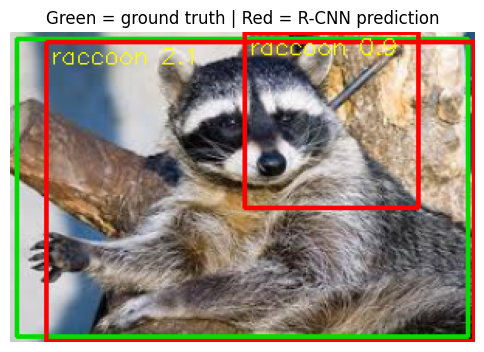

In [ ]:
def nms(boxes, scores, iou_thresh):
    # Non-Max Suppression: returns the indices of the boxes we keep.
    order = np.argsort(-scores)               # best score first
    keep = []
    while len(order) > 0:
        best = order[0]
        keep.append(best)
        if len(order) == 1:
            break
        overlaps = iou_matrix(boxes[best], boxes[order[1:]])[0]
        order = order[1:][overlaps <= iou_thresh]   # drop boxes that overlap the best one too much
    return np.array(keep, dtype=int)


def detect(img, score_thresh=SCORE_THRESH):
    # Full R-CNN inference on one image. Returns (boxes, scores).
    proposals = get_proposals(img, max_boxes=MAX_TEST_PROPOSALS)           # Step 1
    feats  = extract_features(img, proposals)                              # Step 2
    scores = svm.decision_function(feats)                                  # Step 3

    keep = scores > score_thresh
    if keep.sum() == 0:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0)
    boxes, scores, feats = proposals[keep], scores[keep], feats[keep]

    boxes = decode_boxes(boxes, bbox_reg.predict(feats), img.shape)        # Step 4: refine boxes
    keep  = nms(boxes, scores, NMS_IOU)                                    # remove duplicates
    return boxes[keep], scores[keep]


def draw_detections(img, gt_boxes, boxes, scores):
    # Return a copy of img with ground truth (green) and predictions (red) drawn on it.
    out = img.copy()
    for (x1, y1, x2, y2) in gt_boxes.astype(int):
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 220, 0), 2)
    for (x1, y1, x2, y2), s in zip(boxes.astype(int), scores):
        cv2.rectangle(out, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(out, f"raccoon {s:.1f}", (x1 + 3, max(y1 + 14, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
    return out


# ---- try it on one test image ----
test_names = test["image_names"].drop_duplicates().tolist()[:NUM_TEST_IMAGES]
im, gt = load_image(test_names[0], test)
t0 = time.time()
boxes, scores = detect(im)
print(f"{test_names[0]}: {len(boxes)} detection(s) in {time.time() - t0:.2f} s")

plt.figure(figsize=(6, 5))
plt.imshow(draw_detections(im, gt, boxes, scores))
plt.title("Green = ground truth | Red = R-CNN prediction")
plt.axis("off")
plt.show()

### 5.8 Running inference on the test set and saving predictions (Manual Section 5.4)
Like `test_frcnn.py` in the manual, we predict on every test image and **save the result images in a new folder** (`predictions/`). We use a low score threshold (-0.5) here so we can later study how the threshold changes precision and recall, and apply `SCORE_THRESH` only when drawing/saving.

In [ ]:
os.makedirs("predictions", exist_ok=True)

all_dets   = []      # every detection: (image_index, score, box)
gt_by_img  = {}      # ground-truth boxes of every test image
times      = []      # prediction time per image
saved_imgs = []

for i, name in enumerate(test_names):
    im, gt = load_image(name, test)
    gt_by_img[i] = gt

    t0 = time.time()
    boxes, scores = detect(im, score_thresh=-0.5)         # low threshold on purpose (see above)
    times.append(time.time() - t0)

    for b, s in zip(boxes, scores):
        all_dets.append((i, float(s), b))

    # save the picture with only the confident detections drawn
    confident = scores > SCORE_THRESH
    result = draw_detections(im, gt, boxes[confident], scores[confident])
    cv2.imwrite(f"predictions/{name}", cv2.cvtColor(result, cv2.COLOR_RGB2BGR))
    saved_imgs.append((name, result))

print(f"Predicted {len(test_names)} test images -> saved in the 'predictions/' folder")
print(f"Average prediction time per image: {np.mean(times):.2f} s")

Predicted 40 test images -> saved in the 'predictions/' folder
Average prediction time per image: 1.01 s


### 5.9 Evaluation
Looking at pictures is nice, but we also want numbers. A predicted box counts as a **correct detection (True Positive)** if it overlaps a ground-truth box with **IoU ≥ 0.5** and that ground-truth box was not already matched by a better-scoring box. Otherwise it is a **False Positive**. Ground-truth boxes that were never found are **False Negatives**.

* **Precision** = TP / (TP + FP) → "of the boxes I drew, how many were right?"
* **Recall** = TP / (TP + FN) → "of all real raccoons, how many did I find?"
* **AP@0.5 (Average Precision)** → one number summarizing the precision/recall trade-off over all score thresholds (higher is better, max = 1.0).

In [ ]:
def match_detections(dets, gt_by_img, iou_thr=0.5):
    # Sort detections by score (best first) and mark each one as TP (1) or FP (0).
    dets = sorted(dets, key=lambda d: -d[1])
    matched = {i: np.zeros(len(g), dtype=bool) for i, g in gt_by_img.items()}
    is_tp = np.zeros(len(dets))
    for k, (i, score, box) in enumerate(dets):
        g = gt_by_img[i]
        if len(g) == 0:
            continue
        ious = iou_matrix(box, g)[0]
        j = ious.argmax()
        if ious[j] >= iou_thr and not matched[i][j]:
            is_tp[k] = 1
            matched[i][j] = True
    scores = np.array([d[1] for d in dets])
    return scores, is_tp


def average_precision(is_tp, n_gt):
    # Area under the precision-recall curve.
    if len(is_tp) == 0:
        return 0.0
    tp = np.cumsum(is_tp);  fp = np.cumsum(1 - is_tp)
    recall, precision = tp / n_gt, tp / (tp + fp)
    mrec = np.concatenate([[0], recall, [1]])
    mpre = np.concatenate([[0], precision, [0]])
    for k in range(len(mpre) - 2, -1, -1):                 # make precision "monotonic"
        mpre[k] = max(mpre[k], mpre[k + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))


n_gt = sum(len(g) for g in gt_by_img.values())
det_scores, is_tp = match_detections(all_dets, gt_by_img)

print(f"Test images: {len(test_names)}   |   ground-truth raccoons: {n_gt}   |   candidate detections: {len(all_dets)}\n")
print(f"AP@0.5 = {average_precision(is_tp, n_gt):.3f}\n")

# precision / recall for different score thresholds
rows = []
for th in [-0.5, 0.0, 0.5, 1.0, 1.5]:
    n = int((det_scores > th).sum())
    tp = int(is_tp[:n].sum());  fp = n - tp;  fn = n_gt - tp
    prec = tp / max(tp + fp, 1);  rec = tp / max(n_gt, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)
    rows.append([th, n, tp, fp, fn, round(prec, 2), round(rec, 2), round(f1, 2)])
pd.DataFrame(rows, columns=["score threshold", "detections", "TP", "FP", "FN", "precision", "recall", "F1"])

Test images: 40   |   ground-truth raccoons: 44   |   candidate detections: 147

AP@0.5 = 0.734



,score threshold,detections,TP,FP,FN,precision,recall,F1
0,-0.5,147,40,107,4,0.27,0.91,0.42
1,0.0,80,38,42,6,0.47,0.86,0.61
2,0.5,58,36,22,8,0.62,0.82,0.71
3,1.0,42,32,10,12,0.76,0.73,0.74
4,1.5,35,28,7,16,0.80,0.64,0.71


### 5.10 Visualizing the predictions
**Green** = ground truth, **red** = what our R-CNN predicted (with its SVM score).

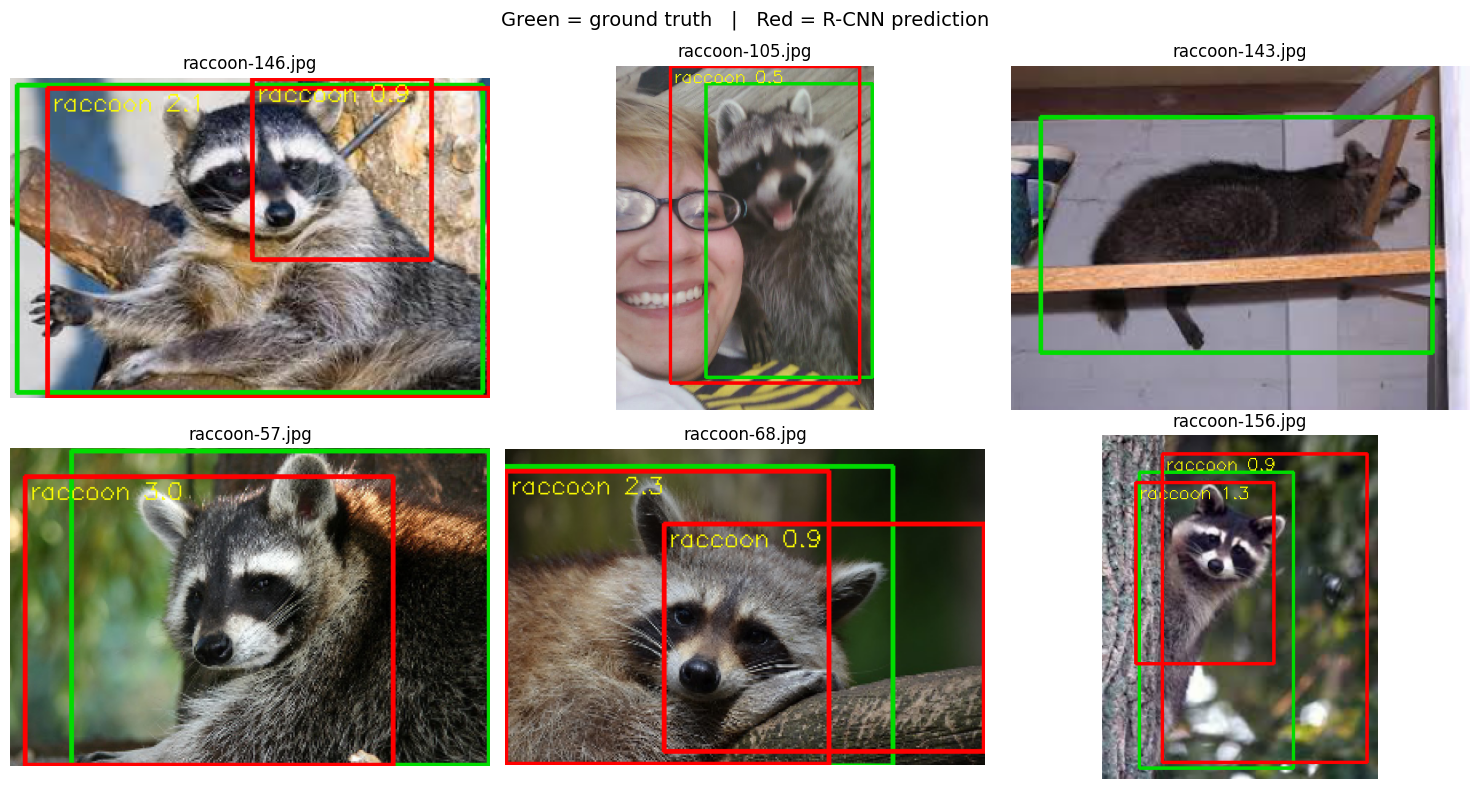

In [ ]:
n_show = min(6, len(saved_imgs))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, result) in zip(axes.ravel(), saved_imgs[:n_show]):
    ax.imshow(result)
    ax.set_title(name)
    ax.axis("off")
for ax in axes.ravel()[n_show:]:
    ax.axis("off")
plt.suptitle("Green = ground truth   |   Red = R-CNN prediction", fontsize=14)
plt.tight_layout()
plt.show()

## 6. R-CNN vs Fast R-CNN vs Faster R-CNN (Manual Section 2.4)

We measured the time our R-CNN needs per image and put it next to the manual's comparison table.

In [ ]:
comparison = pd.DataFrame({
    "Algorithm": ["R-CNN", "Fast R-CNN", "Faster R-CNN"],
    "Region proposals": ["Selective Search", "Selective Search", "Region Proposal Network (RPN)"],
    "CNN passes per image": ["one per region (~2000)", "one for the whole image", "one for the whole image"],
    "Models to train": ["3 (CNN, SVM, box regressor)", "1 (single network)", "1 (single network)"],
    "Prediction time / image (manual)": ["40-50 seconds", "2 seconds", "0.2 seconds"],
})
display(comparison)

print(f"\nOur implementation: {np.mean(times):.2f} s per image  "
      f"(small {MAX_SIDE}px images, max {MAX_TEST_PROPOSALS} regions, device = {device}).")

,Algorithm,Region proposals,CNN passes per image,Models to train,Prediction time / image (manual)
0,R-CNN,Selective Search,one per region (~2000),"3 (CNN, SVM, box regressor)",40-50 seconds
1,Fast R-CNN,Selective Search,one for the whole image,1 (single network),2 seconds
2,Faster R-CNN,Region Proposal Network (RPN),one for the whole image,1 (single network),0.2 seconds



Our implementation: 1.01 s per image  (small 300px images, max 300 regions, device = cuda).


## 7. Conclusion

* We chose the **Raccoon Detection dataset** (https://github.com/datitran/raccoon_dataset) and explored it the same way the manual explores BCCD: CSV inspection, class counts and ground-truth boxes.
* We implemented the **complete R-CNN pipeline** from scratch:
  1. **Selective Search** generates region proposals,
  2. each region is **warped** to 224×224 and passed through a **pre-trained CNN (ResNet-18)** to get features,
  3. a **linear SVM** classifies each region as *raccoon* or *background*,
  4. a **ridge-regression bounding-box regressor** refines the box, and **NMS** removes duplicate detections.
* We evaluated with **IoU, precision, recall and AP@0.5**, and saved the predicted images into the `predictions/` folder.
* R-CNN works, but it must run the CNN **once for every region**, which is why it is slow. Fast R-CNN (one CNN pass + RoI Pooling) and Faster R-CNN (RPN instead of Selective Search) were invented to fix exactly this.

### Ideas to improve the results (optional)
| Idea | How |
|---|---|
| More data | Increase `NUM_TRAIN_IMAGES` to 160 and `NUM_TEST_IMAGES` to 40 |
| More regions at test time | Increase `MAX_TEST_PROPOSALS` |
| Tune the SVM | Try `C = 0.001, 0.1, 1` in the `LinearSVC` cell |
| Hard-negative mining | Re-train the SVM after adding the false positives it produced on the training images |
| Fine-tune the CNN | Un-freeze ResNet-18 and train it on warped region crops (the original R-CNN does this) |
| Bigger CNN | Replace `resnet18` with `resnet50` or `vgg16` and change the feature size (512) accordingly |